<a href="https://colab.research.google.com/github/Mega19-M/Housing-Price-Predictor/blob/main/Housing_Price_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOUSING PRICE PREDICTOR USING LINEAR REGRESSION

**Name:** Mega M

**Internship Domain:** Artificial Intelligence and Machine Learning (AI/ML)

**Internship Task:** Housing Price Predictor

**Objective:** To develop a Machine Learning model to predict housing prices using Linear Regression.

**Dataset:** California Housing Dataset

**Algorithm:** Linear Regression

**Programming Language:** Python

**Platform:** Google Colab

**Libraries Used:** NumPy, Pandas, Matplotlib, Scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:
# Load the dataset
housing = fetch_california_housing()

# Convert into a DataFrame
df = pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

# Add target column
df["MedHouseVal"] = housing.target

# Display first 5 rows
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [ ]:
# Display dataset shape
print("Dataset Shape:", df.shape)

# Display column names
print("\nFeatures:")
print(df.columns)

# Display first 5 rows
print("\nFirst 5 rows:")
print(df.head())

# Display statistical information
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (20640, 9)

Features:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Statistical Summary:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


### Selected Features

- **AveRooms:** Average number of rooms per household.
- **AveBedrms:** Average number of bedrooms per household.
- **HouseAge:** Average age of houses in a district.

**Target Variable:** MedHouseVal – Median house value.

In [ ]:
# Select input features
X = df[["AveRooms", "AveBedrms", "HouseAge"]]

# Select target variable
y = df["MedHouseVal"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   AveRooms  AveBedrms  HouseAge
0  6.984127   1.023810      41.0
1  6.238137   0.971880      21.0
2  8.288136   1.073446      52.0
3  5.817352   1.073059      52.0
4  6.281853   1.081081      52.0

Target Values:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (16512, 3)
Testing Data: (4128, 3)


In [ ]:
# Create Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict house prices
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(results.head(10))

   Actual Price  Predicted Price
0       0.47700         1.712775
1       0.45800         1.790889
2       5.00001         1.764132
3       2.18600         2.281105
4       2.78000         2.289261
5       1.58700         1.966246
6       1.98200         2.458406
7       1.57500         2.130564
8       3.40000         1.282514
9       4.46600         2.962626


### Model Performance Analysis

The model achieved an R² score of approximately 0.1382, indicating that the selected features explain about 13.82% of the variation in housing values.

The model can be improved by including additional relevant features such as median income, population and geographical location.

In [ ]:
# Calculate MSE
mse = mean_squared_error(y_test, y_pred)

# Calculate R2 Score
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Squared Error: 1.1293479456543203
R2 Score: 0.13817139197995776


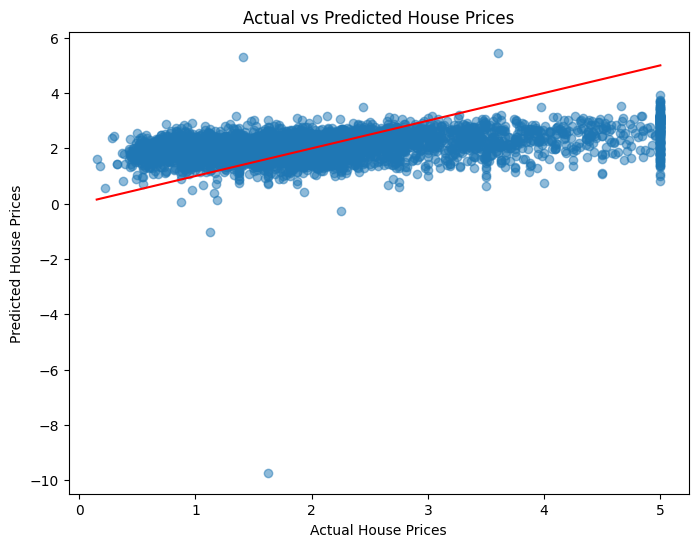

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.show()

In [ ]:
# New house information
new_house = pd.DataFrame({
    "AveRooms": [6.0],
    "AveBedrms": [1.2],
    "HouseAge": [25]
})

# Predict price
predicted_price = model.predict(new_house)

print("Predicted House Value:",
      predicted_price[0] * 100000)

print("Predicted Price in USD")

Predicted House Value: 203855.90771611987
Predicted Price in USD


### Conclusion

The Housing Price Predictor was successfully developed using Linear Regression and the California Housing Dataset.

The model was trained using 80% of the dataset and tested using the remaining 20%. Its performance was evaluated using Mean Squared Error (MSE) and R² Score.

A scatter plot was also created to compare actual and predicted house prices. This project demonstrates the basic working process of a Machine Learning model, including data preprocessing, model training, prediction and evaluation.
